# Skin Lesion Pipeline Demo (Synthetic Patches)

**This is a pipeline demo, not a clinical model.** I want to be loud about that up front. The real HAM10000 dataset is gated and I don't have access, so the images here are synthetic colored patches that vaguely mimic the benign-vs-malignant intensity/texture split. No medical claims of any kind should be read out of this notebook.

What I'm actually showing: the end-to-end PyTorch pipeline you'd use if you *did* have HAM10000 — dataset class, small CNN, training loop, evaluation.

In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Synthesizing the patches

200 fake "skin patches" at 48x48. Benign patches are mostly uniform light-tan with mild gaussian noise. Malignant patches add an irregular darker blob (mimicking an asymmetric pigmented lesion). This is *not* what HAM10000 looks like — it's a stand-in so the rest of the pipeline has shapes to consume.

imgs: (200, 48, 48, 3) labels mean: 0.5


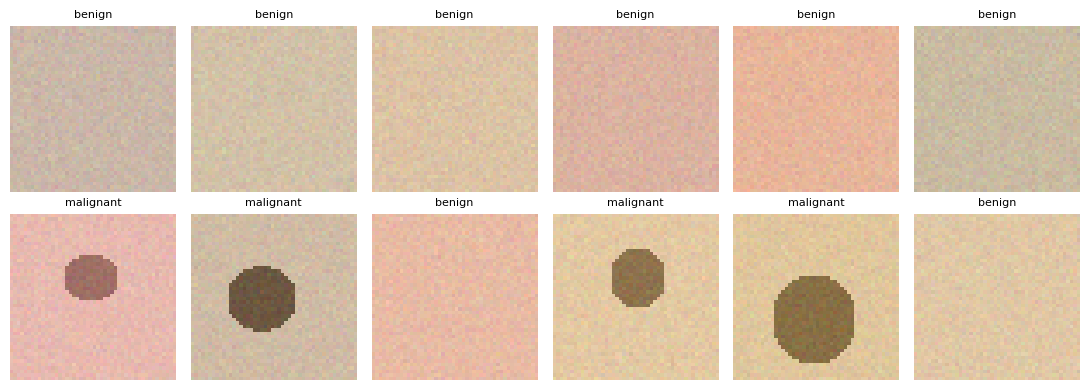

In [2]:
def make_patch(label, size=48, rng=None):
    rng = rng or np.random
    # base "skin" color, light tan, channel-wise jitter
    base = np.array([220, 190, 160]) + rng.normal(0, 8, 3)
    img = np.ones((size, size, 3)) * base
    img += rng.normal(0, 6, img.shape)
    if label == 1:
        # add an irregular dark blob
        cx, cy = rng.randint(15, size-15, 2)
        r = rng.randint(6, 14)
        yy, xx = np.ogrid[:size, :size]
        # asymmetry: stretch the mask
        mask = ((xx - cx) ** 2 / (r ** 2) + (yy - cy) ** 2 / ((r * rng.uniform(0.5, 1.5)) ** 2)) < 1
        darken = rng.uniform(60, 110)
        img[mask] -= darken
    return np.clip(img, 0, 255).astype(np.uint8)

rng = np.random.RandomState(0)
N = 200
imgs = np.stack([make_patch(i % 2, rng=rng) for i in range(N)])
labels = np.array([i % 2 for i in range(N)])

# shuffle once so train/test isn't striped
order = rng.permutation(N)
imgs, labels = imgs[order], labels[order]
print("imgs:", imgs.shape, "labels mean:", labels.mean())

fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(imgs[i])
    ax.set_title("malignant" if labels[i] else "benign", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

## Dataset + small CNN

In [3]:
class LesionDataset(Dataset):
    def __init__(self, imgs, labels):
        self.x = torch.tensor(imgs.transpose(0, 3, 1, 2) / 255.0, dtype=torch.float32)
        self.y = torch.tensor(labels, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]

ds = LesionDataset(imgs, labels)
n_train = int(0.7 * len(ds))
train_ds, test_ds = random_split(ds, [n_train, len(ds) - n_train], generator=torch.Generator().manual_seed(0))
train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)
test_dl  = DataLoader(test_ds, batch_size=32)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten(), nn.Linear(64, 2),
        )
    def forward(self, x): return self.net(x)

model = SmallCNN().to(device)
print(sum(p.numel() for p in model.parameters()), "params")

23714 params


## Train 5 epochs

In [4]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

# 5 epochs is plenty for this synthetic task — overshoots and overfits quickly
for ep in range(5):
    model.train(); running = 0.0; n = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward(); opt.step()
        running += loss.item() * x.size(0); n += x.size(0)
    print(f"ep {ep+1}  train_loss={running/n:.3f}")

model.eval()
all_y, all_p, all_score = [], [], []
with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)
        logits = model(x)
        score = F.softmax(logits, 1)[:, 1].cpu().numpy()
        all_y.extend(y.tolist())
        all_p.extend(logits.argmax(1).cpu().tolist())
        all_score.extend(score.tolist())

print("\nclassification report:")
print(classification_report(all_y, all_p, target_names=["benign", "malignant"]))
try:
    print(f"auc: {roc_auc_score(all_y, all_score):.3f}")
except ValueError:
    pass
print("confusion matrix:")
print(confusion_matrix(all_y, all_p))

ep 1  train_loss=0.696


ep 2  train_loss=0.692


ep 3  train_loss=0.691


ep 4  train_loss=0.686


ep 5  train_loss=0.677

classification report:
              precision    recall  f1-score   support

      benign       0.81      0.97      0.88        31
   malignant       0.96      0.76      0.85        29

    accuracy                           0.87        60
   macro avg       0.88      0.86      0.86        60
weighted avg       0.88      0.87      0.86        60

auc: 0.960
confusion matrix:
[[30  1]
 [ 7 22]]


## Disclaimer (repeating because it matters)

The numbers above are on **fake patches I generated**. The malignant class differs from the benign class in a way that's trivially separable (a dark blob vs no dark blob) — a small CNN should ace this. That high accuracy is a property of the toy data, *not* evidence the pipeline would generalize to real dermoscopy images.

If I were to do this for real:
- Apply for HAM10000 access. The label space is 7-way, not 2-way, and the class imbalance is severe.
- Use a pretrained backbone (EfficientNet-B0 or ConvNeXt-tiny) and fine-tune, not train from scratch on 200 patches.
- Report sensitivity per class with confidence intervals, not just overall accuracy. False negatives on melanoma cost a lot more than false positives.
- Have a dermatologist look at the failure cases. *Then* maybe call it a model.